# ForaDoPico — demonstração do pipeline de IA

Assistente de **lotação e melhor horário** das Linhas 1-Azul e 3-Vermelha do Metrô-SP.
Este notebook roda o pipeline ponta a ponta: base → busca → RAG → ferramenta → agente → recall.

**Pré-requisitos:** Ollama aberto, base indexada (`python ingest.py`). Rode as células na ordem.

In [1]:
import os, sys, json
# garante que o cwd seja a raiz do projeto (o notebook vive em notebooks/)
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())
print('cwd:', os.getcwd())

cwd: c:\Users\lucca\OneDrive\Área de Trabalho\AI


## 1. Base de conhecimento
Gerada do CSV `vw_app_lotacao_prevista` (camada Ouro).

In [2]:
base = json.load(open('base/base_conhecimento.json', encoding='utf-8'))
print('trechos na base:', len(base))
print('exemplo:', base[0]['id'])
print(base[0]['texto'])

trechos na base: 289
exemplo: lot-vila-matilde-quarta-l3
Vila Matilde (Linha 3-Vermelha), Quarta: pico as 07:00 (Crítico, 1031 entradas previstas); melhor horario para entrar as 23:00 (Vazio).


## 2. Busca (retrieval)
Top-3 trechos mais próximos da pergunta, com similaridade.

In [3]:
from rag import buscar
for t in buscar('Qual o horario de pico na Se na segunda?'):
    print(f"{t['similaridade']:.3f}  {t['id']}")

Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
Failed to send telemetry event CollectionQueryEvent: capture() takes 1 positional argument but 3 were given


0.619  lot-se-segunda-l1
0.618  lot-se-segunda-l3
0.580  lot-se-terca-l3


## 3. RAG simples — geração fundamentada em JSON
Responde pelo trecho recuperado; recusa quando está fora da cobertura.

In [4]:
from rag import responder
for p in ['Qual o melhor horario para entrar em Itaquera na terca?',
          'Qual a lotacao na Linha 4-Amarela?']:
    print(json.dumps(responder(p), ensure_ascii=False, indent=2))
    print('-'*50)

{
  "pergunta": "Qual o melhor horario para entrar em Itaquera na terca?",
  "resposta": "Nao consta na base. Este assistente cobre apenas a lotacao das Linhas 1-Azul e 3-Vermelha do Metro-SP, de janeiro a setembro de 2026.",
  "fonte": null,
  "confianca": 0.604,
  "status": "nao_consta"
}
--------------------------------------------------
{
  "pergunta": "Qual a lotacao na Linha 4-Amarela?",
  "resposta": "Nao consta na base. Este assistente cobre apenas a lotacao das Linhas 1-Azul e 3-Vermelha do Metro-SP, de janeiro a setembro de 2026.",
  "fonte": null,
  "confianca": 0.48,
  "status": "nao_consta"
}
--------------------------------------------------


## 4. Ferramenta — número exato do CSV
`consultar_lotacao(estacao, dia, horario)` devolve o valor exato por faixa.

In [5]:
from ferramentas import consultar_lotacao
print(consultar_lotacao('Corinthians-Itaquera', 'terca', '07:00'))
print(consultar_lotacao('Paulista', 'segunda', '08:00'))  # fora da base

{'encontrado': True, 'estacao': 'Corinthians-Itaquera', 'linha': '3-Vermelha', 'dia': 'Terça', 'faixa': '07:00', 'entradas_previstas': 2495, 'indice_lotacao': 1.0, 'categoria': 'Crítico'}
{'encontrado': False, 'estacao': 'Paulista', 'dia': 'Segunda', 'faixa': '08:00'}


## 5. Agente — usa a ferramenta quando há horário
Número exato quando a pergunta cita um horário; senão, cai no RAG.

In [6]:
from agente import responder_agente
for p in ['Quantas pessoas entram em Corinthians-Itaquera na terca as 7h?',
          'Qual o horario de pico na Se na segunda?']:
    print(json.dumps(responder_agente(p), ensure_ascii=False, indent=2))
    print('-'*50)

{
  "pergunta": "Quantas pessoas entram em Corinthians-Itaquera na terca as 7h?",
  "resposta": "Em Corinthians-Itaquera (Linha 3-Vermelha), Terça as 07:00: 2495 entradas previstas, categoria Crítico (indice 1.0). Obs.: o horario e estimado por um perfil (picos as 07:00 e 18:00).",
  "fonte": "lot-corinthians-itaquera-terca-l3",
  "confianca": 1.0,
  "status": "ok",
  "ferramenta": "consultar_lotacao"
}
--------------------------------------------------
{
  "pergunta": "Qual o horario de pico na Se na segunda?",
  "resposta": "07:00",
  "fonte": "lot-se-segunda-l1",
  "confianca": 0.619,
  "status": "ok",
  "ferramenta": null
}
--------------------------------------------------


## 6. Recall da busca (item 03)
Para cada pergunta de escopo, o trecho esperado está no top-1 / top-3?

In [7]:
testset = json.load(open('avaliacao/testset.json', encoding='utf-8'))
ok = [q for q in testset if q['status_esperado'] == 'ok']
a1 = a3 = 0
for q in ok:
    ids = [t['id'] for t in buscar(q['pergunta'])]
    a1 += q['fonte_esperada'] == ids[0]
    a3 += q['fonte_esperada'] in ids[:3]
print(f'recall@1 = {a1}/{len(ok)} = {a1/len(ok):.0%}')
print(f'recall@3 = {a3}/{len(ok)} = {a3/len(ok):.0%}')

recall@1 = 24/24 = 100%
recall@3 = 24/24 = 100%


## 7. Placar das 3 configurações (item 06)
Resultado salvo por `comparar_configs.py`.

In [8]:
placar = json.load(open('avaliacao/placar.json', encoding='utf-8'))
print(f"{'config':<14}{'resposta':>10}{'num_exato':>11}{'recusa':>9}{'acuracia':>10}")
for r in placar:
    print(f"{r['config']:<14}{r['resposta_correta']:>9.0%}{r['exato_correto']:>11.0%}"
          f"{r['recusa_correta']:>9.0%}{r['acuracia']:>10.0%}")

config          resposta  num_exato   recusa  acuracia
sem_contexto         0%         0%      40%        7%
rag_simples         67%         0%     100%       72%
agente              96%        88%     100%       97%


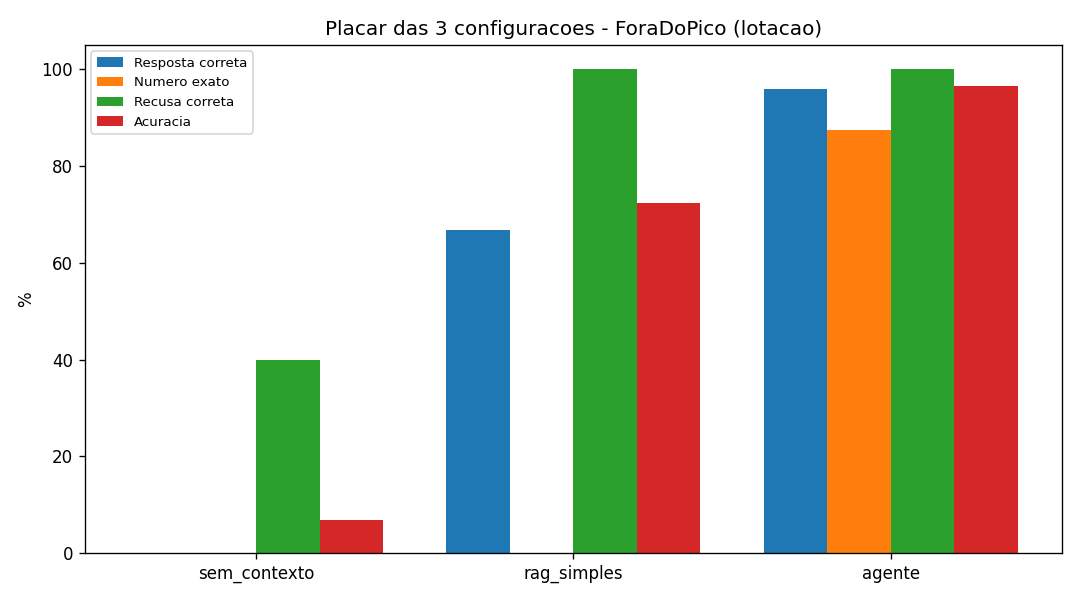

In [9]:
from IPython.display import Image
Image('avaliacao/placar.png')